In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('auto-mpg.csv')
X = df[['displacement']].values
y = df['mpg'].values

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
degrees = [1, 2, 3, 4]
results = []
for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    # Evaluate
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)
    results.append({
        'Degree': degree,
        'Train MSE': mean_squared_error(y_train, train_pred),
        'Test MSE': mean_squared_error(y_test, test_pred),
        'Train R2': r2_score(y_train, train_pred),
        'Test R2': r2_score(y_test, test_pred)
})

In [5]:
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 Degree  Train MSE  Test MSE  Train R2  Test R2
      1  22.415703 18.102544  0.642471 0.663311
      2  19.971457 15.107354  0.681457 0.719019
      3  20.881807 16.369649  0.666937 0.695542
      4  23.204335 18.398790  0.629893 0.657802


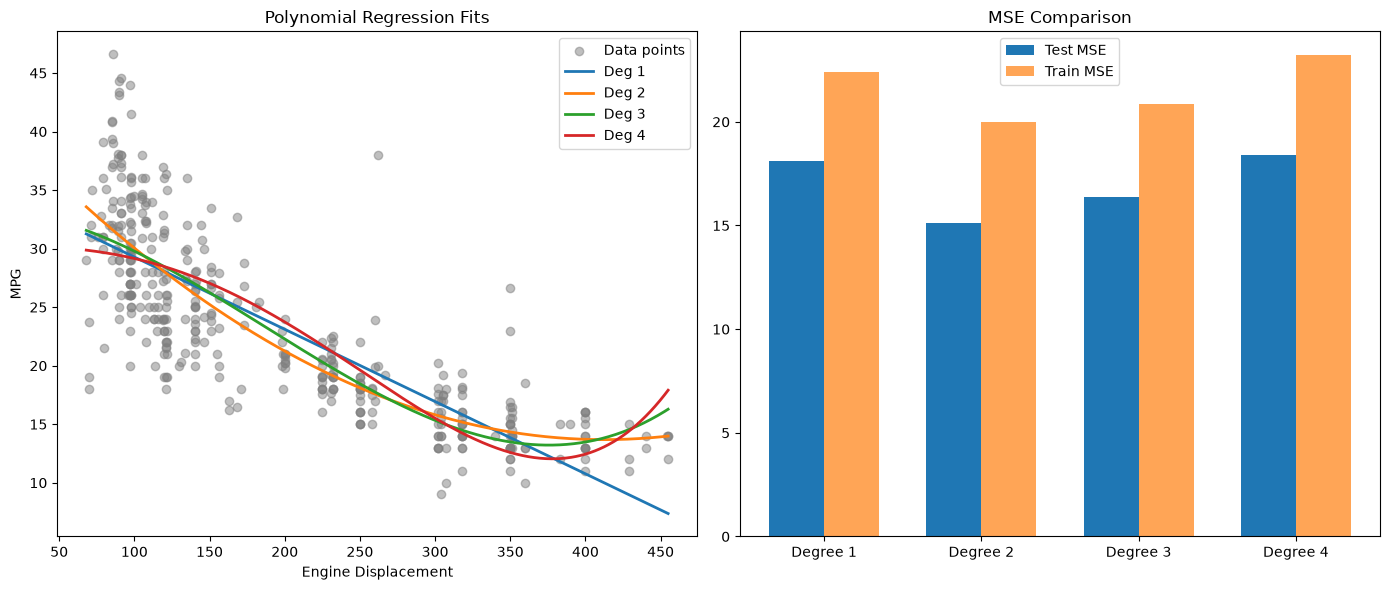

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(X, y, color='gray', alpha=0.5, label='Data points')
X_grid = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    model = LinearRegression().fit(poly.fit_transform(X_train), y_train)
    axes[0].plot(X_grid, model.predict(poly.transform(X_grid)), linewidth=2, label=f'Deg {degree}')
    
axes[0].set_title('Polynomial Regression Fits')
axes[0].set_xlabel('Engine Displacement')
axes[0].set_ylabel('MPG')
axes[0].legend()

x_ind = np.arange(len(degrees))
width = 0.35

axes[1].bar(x_ind - width/2, results_df['Test MSE'], width, label='Test MSE')
axes[1].bar(x_ind + width/2, results_df['Train MSE'], width, label='Train MSE', alpha=0.7)
axes[1].set_xticks(x_ind)
axes[1].set_xticklabels([f'Degree {d}' for d in degrees])
axes[1].set_title('MSE Comparison')
axes[1].legend()

plt.tight_layout()
plt.show()